In [1]:
import mindmap as mm
import os
from pathlib import Path
import nibabel as nib
from skimage import exposure, morphology, filters, measure
import matplotlib.pyplot as plt
import numpy as np

mm.io.read_config("config.yml", env=True)

#### Parameters

In [18]:
sub = "sub-pat23"       # select a subject
mm_dir = Path(os.environ["MM_DIR"])
ksize_opening = 3
ksize_closing = 3

# files
mri_pre = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cmp-v3.0.0-beta-RC1/{sub}/ses-preop/anat/{sub}_ses-preop_res-cmp_desc-brain_T1w.nii.gz"
mri_post = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/cmp-v3.0.0-beta-RC1/{sub}/ses-postop/anat/{sub}_ses-postop_space-individual_desc-brain_T1w.nii.gz"
parc = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/{sub}/parc/{sub}_chimera=laus2018-2.0mm+thal-0.05.nii.gz"
clut = f"/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/{sub}/parc/{sub}_chimera=laus2018-2.0mm+thal-0.05.txt"

# output files
fname_resec = mm_dir/sub/"resec"/f"{sub}_resection-mask.nii.gz"
fname_diff = mm_dir/sub/"resec"/f"{sub}_prepost-diff.mask.nii.gz"
fname_npre = mm_dir/sub/"resec"/f"{sub}_hm-pre.nii.gz"
fname_npost = mm_dir/sub/"resec"/f"{sub}_hm-post.nii.gz"

#### Data

In [19]:
mri_pre = nib.load(mri_pre)
mri_post = nib.load(mri_post)

parc = mm.utils.Parcellation(parc, clut)
gm_mask = parc.create_mask()

Pre-surgery MRI


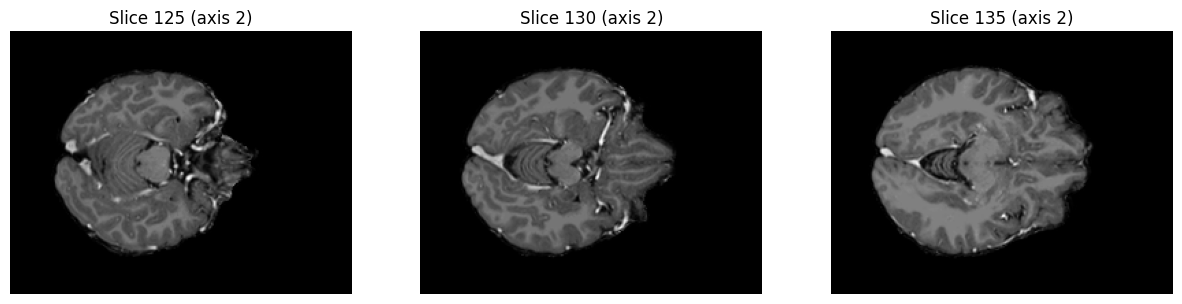

Post-surgery MRI


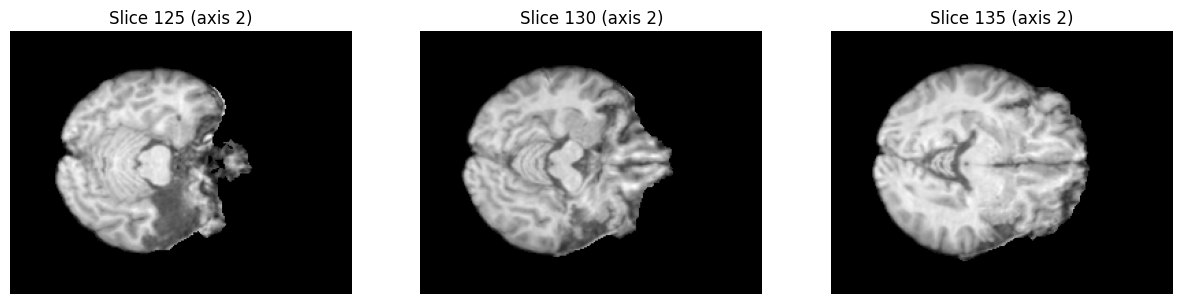

Gray matter mask


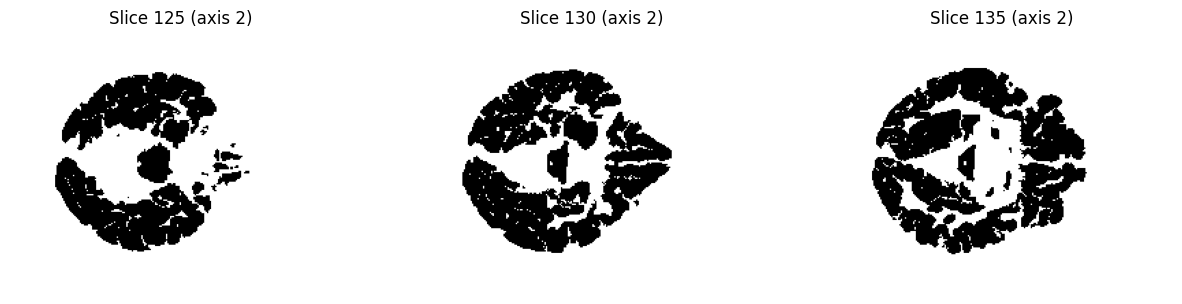

In [20]:
slices = [125, 130, 135]

print("Pre-surgery MRI")
mm.viz.show_slices(mri_pre, slices)

print("Post-surgery MRI")
mm.viz.show_slices(mri_post, slices)

print("Gray matter mask")
mm.viz.show_slices(gm_mask, slices, cmap="binary")

#### Histogram matching

In [21]:
matched_mri_post = exposure.match_histograms(mri_post.get_fdata(), mri_pre.get_fdata())

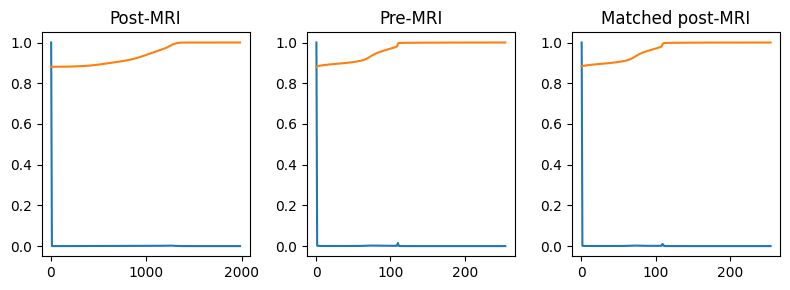

In [22]:
# visualization of Histograms
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(8,3))

for i, img in enumerate((mri_post.get_fdata(), mri_pre.get_fdata(), matched_mri_post)):
    img_hist, bins = exposure.histogram(img)
    axes[i].plot(bins, img_hist / img_hist.max())
    img_cdf, bins = exposure.cumulative_distribution(img)
    axes[i].plot(bins, img_cdf)
    
axes[0].set_title("Post-MRI")
axes[1].set_title("Pre-MRI")
axes[2].set_title("Matched post-MRI")

plt.tight_layout()
plt.show()

#### Difference

In [23]:
mri_diff = np.abs(mri_pre.get_fdata() - matched_mri_post)
mri_diff[mri_diff<mri_diff[0,0,0]+1e-8] = 0     # reset background to 0

MRI difference


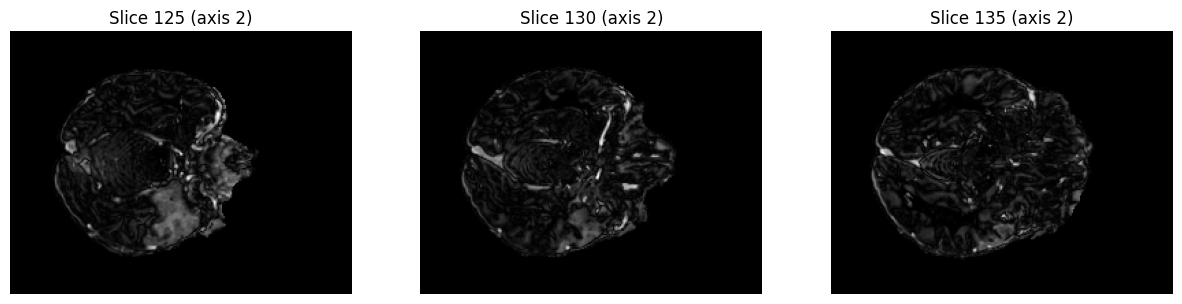

In [24]:
print("MRI difference")
mm.viz.show_slices(mri_diff, slices)

#### Morphological operations

In [25]:
kernel_opening = morphology.ball(ksize_opening)
kernel_closing = morphology.ball(ksize_closing)

mri_morph = morphology.opening(mri_diff, kernel_opening)
mri_morph = morphology.closing(mri_morph, kernel_closing)

MRI after morphological operations


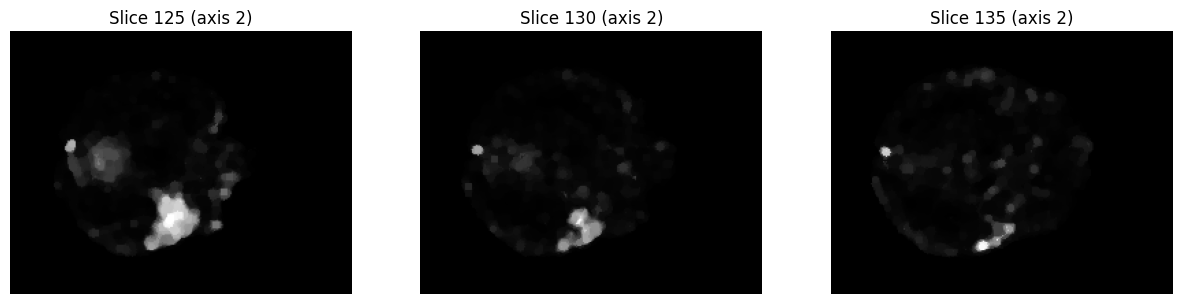

In [26]:
print("MRI after morphological operations")
mm.viz.show_slices(mri_morph, slices)

#### Binarize

In [27]:
thrs_value = filters.threshold_otsu(mri_morph)
mri_bin = mri_morph > thrs_value*1

Mask of MRI difference


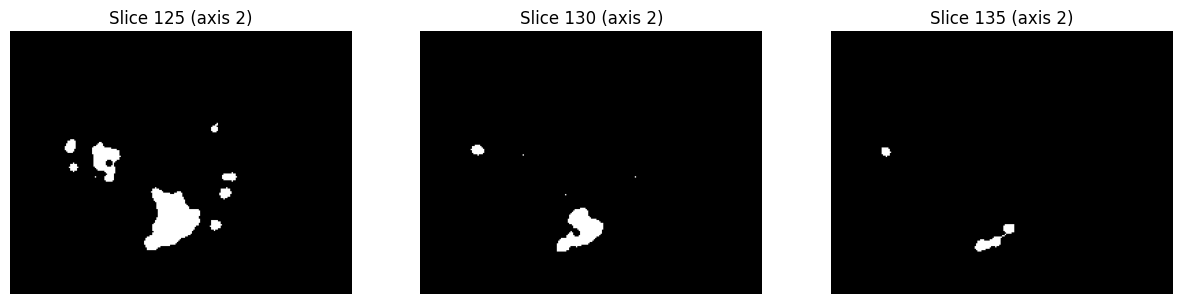

In [28]:
print("Mask of MRI difference")
mm.viz.show_slices(mri_bin, slices)

#### Select largest component

In [53]:
labels = measure.label(mri_bin, connectivity=2)
mri_lcc = labels == np.argmax(np.bincount(labels.flat, weights=mri_bin.flat))

Largest component of MRI difference


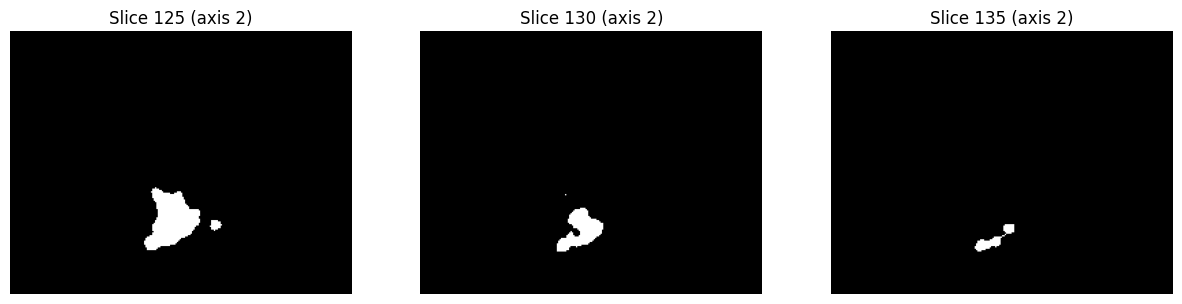

In [54]:
print("Largest component of MRI difference")
mm.viz.show_slices(mri_lcc, slices)

#### Apply gray matter mask

In [55]:
mri_masked = mri_lcc * gm_mask.get_fdata()

Gray matter insided the resection area


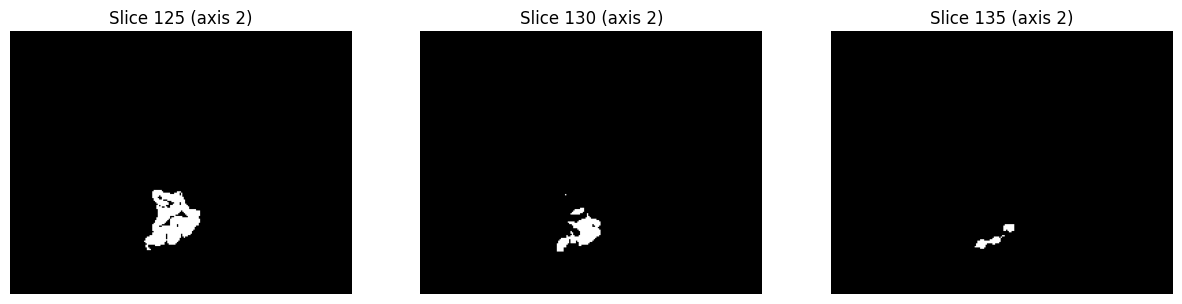

In [56]:
print("Gray matter insided the resection area")
mm.viz.show_slices(mri_masked, slices)

In [57]:
# save
if True:
    folder = Path("/home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/")
    fname = folder/sub/"resec"/f"{sub}_auto-seg.nii.gz"
    img = nib.Nifti1Image(mri_masked, mri_pre.affine)
    nib.save(img, fname)